# FlowLens Gate 2｜KuaiRand-Pure 数据可信度审计

## tl;dr

- 官方归档 MD5 与发布值一致，三份日志合计 **2,622,668** 条原始事件。
- 清洗视图只删除 **21,997** 条完全重复记录，保留 **2,600,671** 条；非完全相同的候选事件键冲突保留并打标。
- 三份清洗日志的 Great Expectations 契约共执行 **129** 条阻断规则，全部通过。
- 数据可进入 FlowLens 基线与分发诊断，但必须禁用无事件日期的整月视频统计特征；Pure 版本也不能用于宣称严谨长序列或线上因果效果。

> 证据边界：本 Notebook 展示公开数据的 E1 观测和确定性 E2 质量标记，不把离线数据包装为真实平台内部数据或线上 A/B 结果。

## Context & Methods

目标是判断 KuaiRand-Pure 是否足以支撑 FlowLens MVP 的分发诊断、推荐基线和策略回放，并将稳定规则固化为可自动阻断的数据契约。

### Key Assumptions

- 事件粒度按源文件“一行一次用户—视频曝光／交互记录”理解。
- `user_id + video_id + time_ms` 只是候选事件键，非完全相同冲突不会被自动删除。
- 日级切分采用源字段 `date`，`time_ms` 仅用于日内排序；两者不一致时保留质量标记。
- `long_view` 保留官方标签，公开公式复算只做敏感性检查。
- `video_features_statistic_pure.csv` 缺少事件日期，默认禁止进入任何时间切分训练／验证／测试。

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "reports" / "data-quality").exists() else cwd.parent
REPORT_DIR = PROJECT_ROOT / "reports" / "data-quality"

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (9, 4.8),
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.edgecolor": "#334155",
    "text.color": "#172033",
    "axes.labelcolor": "#172033",
})
PALETTE = {
    "raw": "#2457A6",
    "clean": "#D6A328",
    "duplicate": "#D97706",
    "duration": "#7C8E42",
    "date": "#C04B76",
}

## Data

本 Notebook 不重复扫描 500MB 以上的原始与清洗 CSV，而是读取由全量审计脚本生成的可追溯结果：

- `reports/data-quality/profile.json`：原始日志与实体表全量 profile；
- `reports/data-quality/cleaning_manifest.json`：清洗前后行数与质量标记；
- `reports/data-quality/gx_validation_results.json`：Great Expectations 全量契约结果；
- `reports/data-quality/tab_profile.csv`：按日志和 tab 的消费指标。

复算原始审计：`python scripts/audit_kuairand_pure.py`  
重建清洗视图：`python scripts/prepare_kuairand_event_views.py`  
复跑契约：`python scripts/validate_kuairand_with_gx.py`

In [2]:
profile = json.loads((REPORT_DIR / "profile.json").read_text(encoding="utf-8"))
manifest = json.loads((REPORT_DIR / "cleaning_manifest.json").read_text(encoding="utf-8"))
gx_results = json.loads((REPORT_DIR / "gx_validation_results.json").read_text(encoding="utf-8"))
tab_profile = pd.read_csv(REPORT_DIR / "tab_profile.csv")

log_order = ["standard_early", "standard_late", "random_late"]
summary_rows = []
for log_name in log_order:
    raw = profile["logs"][log_name]
    clean = manifest["logs"][log_name]
    gx_log = gx_results["logs"][log_name]
    summary_rows.append({
        "log": log_name,
        "raw_rows": raw["rows"],
        "clean_rows": clean["clean_rows"],
        "exact_duplicates": raw["exact_duplicate_rows"],
        "duplicate_rate": raw["exact_duplicate_rate"],
        "duration_zero_rate": raw["duration_zero_rate"],
        "date_mismatch_rate": raw["china_date_mismatch_rows"] / raw["rows"],
        "formula_mismatch_valid_rate": raw["long_view_rule_mismatch_valid_duration_rate"],
        "gx_expectations": gx_log["statistics"]["evaluated_expectations"],
        "gx_success": gx_log["success"],
    })

summary = pd.DataFrame(summary_rows)
display(summary.assign(
    duplicate_rate=summary["duplicate_rate"].map(lambda x: f"{x:.2%}"),
    duration_zero_rate=summary["duration_zero_rate"].map(lambda x: f"{x:.2%}"),
    date_mismatch_rate=summary["date_mismatch_rate"].map(lambda x: f"{x:.2%}"),
    formula_mismatch_valid_rate=summary["formula_mismatch_valid_rate"].map(lambda x: f"{x:.2%}"),
))

,log,raw_rows,clean_rows,exact_duplicates,duplicate_rate,duration_zero_rate,date_mismatch_rate,formula_mismatch_valid_rate,gx_expectations,gx_success
0,standard_early,1141112,1125503,15609,1.37%,2.11%,0.81%,0.24%,43,True
1,standard_late,295497,289119,6378,2.16%,1.62%,0.92%,0.25%,43,True
2,random_late,1186059,1186049,10,0.00%,3.11%,0.73%,0.11%,43,True


In [3]:
assert profile["archive"]["checksum_status"] == "PASS"
assert profile["archive"]["actual_md5"] == profile["archive"]["expected_md5"]
assert summary["raw_rows"].sum() == 2_622_668
assert summary["clean_rows"].sum() == 2_600_671
assert summary["exact_duplicates"].sum() == 21_997
assert gx_results["success"] is True
assert summary["gx_expectations"].sum() == 129
assert summary["gx_success"].all()

join_coverage = profile["join_coverage"]
join_coverage

{'log_users': 27285,
 'log_videos': 7583,
 'missing_user_feature_keys': 0,
 'missing_video_basic_keys': 0,
 'missing_video_statistic_keys': 0,
 'user_feature_coverage': 1.0,
 'video_basic_coverage': 1.0,
 'video_statistic_coverage': 1.0}

## Results

### 1. 原始事件与清洗视图

标准曝光日志存在明显的完全重复记录；随机曝光日志几乎没有。清洗只删除整行完全一致的记录，因此不会把合法重复曝光误删。

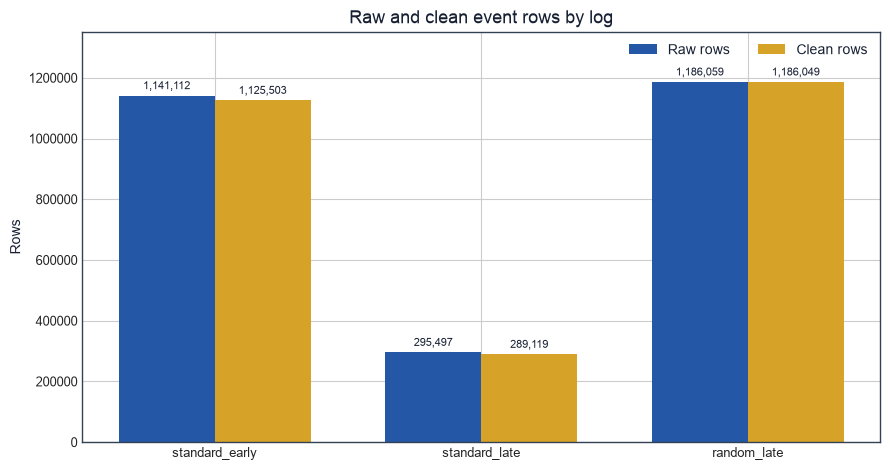

In [4]:
x = np.arange(len(summary))
width = 0.36
fig, ax = plt.subplots()
raw_bars = ax.bar(x - width / 2, summary["raw_rows"], width, label="Raw rows", color=PALETTE["raw"])
clean_bars = ax.bar(x + width / 2, summary["clean_rows"], width, label="Clean rows", color=PALETTE["clean"])
ax.set_title("Raw and clean event rows by log")
ax.set_ylabel("Rows")
ax.set_xticks(x, summary["log"])
ax.ticklabel_format(axis="y", style="plain")
ax.legend(frameon=False, ncol=2)
for bars in [raw_bars, clean_bars]:
    ax.bar_label(bars, labels=[f"{int(v):,}" for v in bars.datavalues], padding=3, fontsize=8)
ax.set_ylim(0, summary["raw_rows"].max() * 1.14)
fig.tight_layout()
plt.show()

### 2. 质量问题的相对规模

三类比例代表不同问题，不能相加：完全重复影响计数；零时长使公式复算不可验证；时间戳日期差异会影响时间切分口径。日期不一致不直接判定源数据错误，因此保留源 `date`。

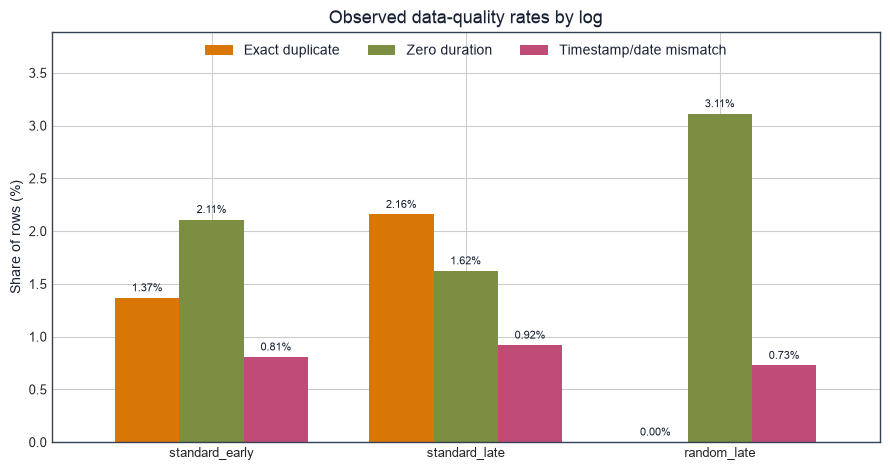

In [5]:
quality_metrics = pd.DataFrame({
    "Exact duplicate": summary.set_index("log")["duplicate_rate"],
    "Zero duration": summary.set_index("log")["duration_zero_rate"],
    "Timestamp/date mismatch": summary.set_index("log")["date_mismatch_rate"],
}) * 100

ax = quality_metrics.plot.bar(
    color=[PALETTE["duplicate"], PALETTE["duration"], PALETTE["date"]],
    width=0.76,
    figsize=(9, 4.8),
)
ax.set_title("Observed data-quality rates by log")
ax.set_ylabel("Share of rows (%)")
ax.set_xlabel("")
ax.set_xticklabels(quality_metrics.index, rotation=0)
ax.legend(frameon=False, ncol=3, loc="upper center")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=8)
ax.set_ylim(0, quality_metrics.to_numpy().max() * 1.25)
plt.tight_layout()
plt.show()

### 3. 标准曝光与随机曝光不可直接当作同一分布

日志的采样策略不同，点击率和长播率存在显著描述性差异。这里仅用于提示选择偏差风险，不解释为策略因果效果，也不据此宣称随机日志“更差”。

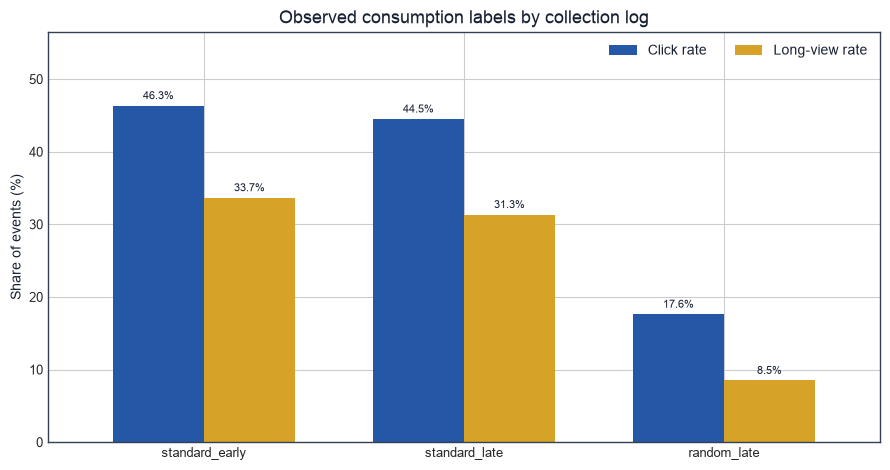

,log,tab,rows,users,videos,click_rate,long_view_rate,hate_rate
30,random_late,1,1178025,27000,7537,0.177286,0.085348,0.001132
32,random_late,11,6755,304,4378,0.000000,0.023686,0.001628
31,random_late,2,764,190,725,0.113874,0.045812,0.007853
33,random_late,14,515,38,498,0.000000,0.062136,0.000000
1,standard_early,1,834876,25121,7231,0.529675,0.386074,0.000449
0,standard_early,0,150013,13785,6063,0.092025,0.042216,0.000327
4,standard_early,4,75524,9832,4322,0.619604,0.489288,0.000384
2,standard_early,2,39291,2194,4951,0.479983,0.380545,0.000534
6,standard_early,6,29671,8043,502,0.180816,0.086954,0.000135
16,standard_late,1,223513,24537,5830,0.498101,0.351622,0.000823


In [6]:
label_rows = []
for log_name in log_order:
    rates = profile["logs"][log_name]["label_rates"]
    label_rows.append({
        "log": log_name,
        "Click rate": rates["is_click"] * 100,
        "Long-view rate": rates["long_view"] * 100,
    })
label_rates = pd.DataFrame(label_rows).set_index("log")

ax = label_rates.plot.bar(color=[PALETTE["raw"], PALETTE["clean"]], width=0.7, figsize=(9, 4.8))
ax.set_title("Observed consumption labels by collection log")
ax.set_ylabel("Share of events (%)")
ax.set_xlabel("")
ax.set_xticklabels(label_rates.index, rotation=0)
ax.legend(frameon=False, ncol=2)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=8)
ax.set_ylim(0, label_rates.to_numpy().max() * 1.22)
plt.tight_layout()
plt.show()

display(tab_profile.sort_values(["log", "rows"], ascending=[True, False]).groupby("log").head(5))

### 4. 自动化契约结果

Great Expectations 对每份清洗日志执行 43 条稳定规则；三份共 129 条，全部通过。已知但不能稳定判断真假的问题保留为质量标记，不被错误地转化为阻断项。

In [7]:
gx_summary = pd.DataFrame([
    {
        "log": name,
        "evaluated": result["statistics"]["evaluated_expectations"],
        "passed": result["statistics"]["successful_expectations"],
        "failed": result["statistics"]["unsuccessful_expectations"],
        "status": "PASS" if result["success"] else "FAIL",
    }
    for name, result in gx_results["logs"].items()
])
display(gx_summary)

,log,evaluated,passed,failed,status
0,standard_early,43,43,0,PASS
1,standard_late,43,43,0,PASS
2,random_late,43,43,0,PASS


## Takeaways

1. **可进入 Gate 3。** 核心字段、标签域、实体关联与清洗视图满足基线开发要求；用户、视频基础表和视频统计表的关联覆盖率均为 100%。
2. **训练边界必须写进代码。** 整月视频统计特征没有事件日期，禁止进入时间切分训练、验证与测试；后续特征必须做 point-in-time 检查。
3. **不把数据缺陷“洗掉”。** 零时长、官方长播公式差异、日期差异与候选事件键冲突均保留审计字段，以便做敏感性分析。
4. **不越过因果边界。** 标准与随机曝光差异是描述性证据；Pure 的不完整顺序日志不足以支持线上增量或严谨长序列结论。
5. **Gate 3 的最小任务。** 固定时间切分、建立 Popularity／ItemCF／轻量多任务基线，并先通过未来信息泄漏测试，再开始策略重排。